# Can run luck be estimated from 1 run?

- Leaderboards publish 1 run per agent, so the share of the variance of a
  score that is run-to-run luck (the run share) is never measured
  - With 1 run, luck cannot be told apart from an agent being good at a
    specific task without a model of the tasks
- This notebook builds the estimator of Study B in `preregistration_2.md`
  and tunes it on the development set, the public EvalPlus samples
  - Our own runs are the test set, used once after the tuned estimator is
    committed, so this notebook never loads them
- The estimator:
  1. Fit a Rasch or 2PL model to an agents x tasks matrix with 1 run per
     agent
  2. Estimate $\sigma^2_{run}$ of an agent as the average over the tasks of
     p (1 - p), with p the fitted chance of a pass, times a calibration
     factor
  3. Divide it by score x (1 - score) to get the run share
- The pedagogical arc:
  - The development set and its true run shares
  - The estimator before tuning
  - Tuning the model, the penalty, the extra agents, and the calibration
  - How many tasks need a second run

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import pandas as pd

import helpers.hdbg as hdbg
import helpers.hnotebook as hnotebook

import skill_vs_luck_runs_utils as rutils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
rutils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpo6pvchqu.json --HistoryManager.hist_file=:memory:


# Part 1: The development set

## Cell 1.1: Load the public samples

- The public EvalPlus samples on HumanEval+ come from 8 models sampled at
  temperatures 0.2 and 0.8, scored on the first 50 of the 200 released
  samples per task
  - Each sample of a task plays the role of 1 run
- 31 public models also have a greedy sample, the possible extra agents
- Only the `evalplus_humaneval_*` files are loaded: the `local_*` files are
  the test set

In [3]:
# Load the public HumanEval+ scores, and none of our runs.
public = rutils.load_scores(
    "data/coding_runs", pattern="evalplus_humaneval_*.csv.gz"
)
hdbg.dassert_eq(public["source"].unique().tolist(), ["evalplus"])
# Keep the models sampled at both temperatures.
temperatures = public.groupby("model")["temperature"].agg(set)
models = sorted(
    model for model, temps in temperatures.items() if {0.2, 0.8} <= temps
)
samples = {
    temperature: {
        model: rutils.get_outcome_matrix(
            public,
            source="evalplus",
            benchmark="humaneval",
            model=model,
            scaffold="one_shot",
            temperature=temperature,
        )
        for model in models
    }
    for temperature in (0.2, 0.8)
}
extras = rutils.get_public_greedy_agents(public, "humaneval")

print("models=", models)
print("samples=", samples[0.2][models[0]].shape, "extras=", extras.shape)
# Outcome: 8 models with 164 tasks x 50 samples at each temperature, and 31
# public greedy agents.

models= ['code-llama-13b', 'code-llama-34b', 'code-llama-7b', 'codegen-16b', 'codet5p-16b', 'mistral-7b', 'phind-code-llama-34b-v2', 'starcoder']
samples= (164, 50) extras= (31, 164)


## Cell 1.2: The true run shares

- The truth of a case (1 model at 1 temperature) is the run share measured
  from all its 50 samples, as in phase 1
- These 16 cases are the development set

In [4]:
# Measure the run share of each case from all its samples.
truth = pd.DataFrame(
    {
        temperature: {
            model: rutils.compute_variance_components(matrix)["run_share"]
            for model, matrix in by_model.items()
        }
        for temperature, by_model in samples.items()
    }
)

display(truth.round(3))
# Outcome: the run share is 15% to 30% at 0.2 and 42% to 55% at 0.8, the same
# numbers as in Part 6 of the runs notebook.

,0.2,0.8
code-llama-13b,0.240,0.521
code-llama-34b,0.296,0.546
code-llama-7b,0.219,0.521
codegen-16b,0.198,0.464
codet5p-16b,0.235,0.481
mistral-7b,0.214,0.533
phind-code-llama-34b-v2,0.151,0.424
starcoder,0.225,0.537


# Part 2: The estimator before tuning

## Cell 2.1: Run a first grid of settings

- Each case gets 30 draws: in each draw, the case and some other sampled
  models get 1 sample drawn at random per task as their 1 run
  - The matrix holds 3 sampled models at 0.2 and 6 at 0.8, like the test
    matrices, which hold our 3 old models at 0.2 and all 6 models at 0.8
  - With `extras`, the matrix also holds the public greedy agents of the
    models that are not in it
  - Every setting sees the same draws
- The setting before any tuning is `rasch 0.01 alone`: Rasch, the penalty
  0.01, and no extra agents
- This cell takes about 6 minutes

In [5]:
# Run the first grid of settings on both temperatures.
N_OTHERS = {0.2: 2, 0.8: 5}
N_DRAWS = 30
UNTUNED = "rasch 0.01 alone"
settings = rutils.get_one_run_settings(
    ["rasch", "2pl"], [0.001, 0.01, 0.1, 1.0], [False, True]
)
untuned = {**settings[UNTUNED], "calibration": 1.0}
hdbg.dassert_eq(untuned, rutils.UNTUNED_ONE_RUN_SETTING)
results = pd.concat(
    [
        rutils.evaluate_one_run_estimator(
            samples[temperature], extras, settings, n_others, n_draws=N_DRAWS
        ).assign(temperature=temperature)
        for temperature, n_others in N_OTHERS.items()
    ],
    ignore_index=True,
)

print("settings=", len(settings), "rows=", len(results))
# Outcome: 16 settings x 16 cases x 30 draws.

Cases:   0%|          | 0/8 [00:00<?, ?it/s]

Cases:  12%|█▎        | 1/8 [00:20<02:24, 20.70s/it]

Cases:  25%|██▌       | 2/8 [00:40<01:59, 19.93s/it]

Cases:  38%|███▊      | 3/8 [01:00<01:39, 19.94s/it]

Cases:  50%|█████     | 4/8 [01:18<01:17, 19.25s/it]

...

Cases:  75%|███████▌  | 6/8 [02:19<00:47, 23.51s/it]

Cases:  88%|████████▊ | 7/8 [02:43<00:23, 23.54s/it]

Cases: 100%|██████████| 8/8 [03:06<00:00, 23.48s/it]

Cases: 100%|██████████| 8/8 [03:06<00:00, 23.34s/it]

settings= 16 rows= 7680


## Cell 2.2: Check the estimator before tuning

- `above` is the share of the draws where the estimate is above the truth
- B2 predicts that the estimate before tuning is above the truth in more
  than half of the 18 phase-2 test cases, since it counts agent-task
  strengths as luck

In [6]:
# Compare the estimate before tuning with the truth, at each temperature.
cases = rutils.summarize_one_run_cases(results, UNTUNED, 1.0)
before = results[results["setting"] == UNTUNED]
by_temperature = cases.groupby(level="temperature")[
    ["truth", "estimate", "within"]
].mean()
by_temperature["above"] = (
    (before["estimate"] > before["truth"]).groupby(before["temperature"]).mean()
)

display(by_temperature.round(3))
# Outcome: before tuning, the estimate is above the truth in 98% of the draws
# at 0.2 (32.5% against 22.2% on average) and in 21% at 0.8 (47.5% against
# 50.3%), so it is within 10 points in 95% of the draws at 0.8 but only 46% at
# 0.2.

,truth,estimate,within,above
temperature,,,,
0.2,0.222,0.325,0.463,0.983
0.8,0.503,0.475,0.950,0.208


## Cell 2.3: Compare the first grid

- The factor of each setting is fit on all 16 cases
- `cv_error` and `cv_within` fit the factor of each model on the other 7
  models, so they estimate the error on a new model
- `mean_0.2` and `mean_0.8` are the mean estimates before calibration, while
  the truth averages 0.222 and 0.503
- Sorted by `cv_error`, the rule for picking the setting

In [7]:
# Summarize the errors of each setting.
summary = rutils.summarize_one_run_errors(results)
# Add the mean estimate before calibration at each temperature.
means = results.groupby(["setting", "temperature"])["estimate"].mean().unstack()
means.columns = [f"mean_{temperature:g}" for temperature in means.columns]

display(summary.join(means).sort_values("cv_error").round(3))
# Outcome: without extra agents, 2PL with the penalty 0.1 and Rasch with 0.001
# are the best, with 5.6 and 5.7 points of error on a new model. With the extra
# agents every setting is worse, within 10 points in at most 45% of the draws:
# their estimate moves by only 1 to 4 points from 0.2 to 0.8, against 15 to 19
# points for the best settings without them and 28 points for the truth, since
# the greedy agents have no run luck and set the task difficulties.

,above,error_raw,factor,error,within,cv_error,cv_within,mean_0.2,mean_0.8
2pl 0.1 alone,0.106,0.098,1.344,0.053,0.875,0.056,0.860,0.187,0.352
rasch 0.001 alone,0.475,0.058,1.041,0.056,0.833,0.057,0.831,0.274,0.454
2pl 0.01 alone,0.004,0.136,1.528,0.059,0.821,0.060,0.806,0.133,0.320
2pl 0.001 alone,0.004,0.147,1.574,0.063,0.798,0.065,0.788,0.124,0.308
rasch 0.01 alone,0.596,0.072,0.984,0.071,0.721,0.072,0.708,0.325,0.475
2pl 0.01 extras,0.506,0.120,1.065,0.120,0.448,0.120,0.435,0.370,0.411
2pl 0.001 extras,0.504,0.120,1.060,0.120,0.425,0.120,0.415,0.367,0.408
2pl 0.1 extras,0.506,0.122,1.058,0.121,0.415,0.121,0.406,0.377,0.415
rasch 0.1 alone,0.996,0.198,0.696,0.124,0.262,0.128,0.262,0.537,0.584
rasch 0.001 extras,0.569,0.139,0.841,0.132,0.204,0.141,0.200,0.441,0.461


# Part 3: Tuning

## Cell 3.1: Run a finer grid without extra agents

- The extra agents made every setting worse, so the finer grid tries more
  penalties without them, around the best ones
- Same draws as the first grid

In [8]:
# Run the finer grid and summarize all the settings.
finer = {
    **rutils.get_one_run_settings(["rasch"], [0.0001, 0.0003, 0.003], [False]),
    **rutils.get_one_run_settings(["2pl"], [0.03, 0.3], [False]),
}
finer_results = pd.concat(
    [
        rutils.evaluate_one_run_estimator(
            samples[temperature], extras, finer, n_others, n_draws=N_DRAWS
        ).assign(temperature=temperature)
        for temperature, n_others in N_OTHERS.items()
    ],
    ignore_index=True,
)
all_settings = {**settings, **finer}
all_results = pd.concat([results, finer_results], ignore_index=True)
all_summary = rutils.summarize_one_run_errors(all_results).sort_values(
    "cv_error"
)

print("settings=", len(all_settings))
display(all_summary.round(4))
# Outcome: the best 3 settings are within 0.1 points of each other: 2PL with
# the penalty 0.1 (5.56 points), Rasch with 0.0001 (5.59), and Rasch with
# 0.0003 (5.62). Rasch stays between 5.6 and 6.1 points for penalties up to
# 0.003, while 2PL breaks down at 0.3 (9.35 points).

Cases:   0%|          | 0/8 [00:00<?, ?it/s]

Cases:  12%|█▎        | 1/8 [00:01<00:11,  1.66s/it]

Cases:  25%|██▌       | 2/8 [00:03<00:09,  1.66s/it]

Cases:  38%|███▊      | 3/8 [00:04<00:08,  1.65s/it]

Cases:  50%|█████     | 4/8 [00:06<00:06,  1.67s/it]

...

Cases:  88%|████████▊ | 7/8 [00:20<00:02,  2.94s/it]

Cases: 100%|██████████| 8/8 [00:23<00:00,  2.97s/it]

Cases: 100%|██████████| 8/8 [00:23<00:00,  2.97s/it]

settings= 21


,above,error_raw,factor,error,within,cv_error,cv_within
2pl 0.1 alone,0.1062,0.0975,1.3444,0.0532,0.8750,0.0556,0.8604
rasch 0.0001 alone,0.4458,0.0572,1.0470,0.0548,0.8354,0.0559,0.8354
rasch 0.0003 alone,0.4542,0.0574,1.0456,0.0551,0.8375,0.0562,0.8333
2pl 0.03 alone,0.0125,0.1258,1.4769,0.0550,0.8396,0.0570,0.8250
rasch 0.001 alone,0.4750,0.0579,1.0414,0.0563,0.8333,0.0573,0.8312
2pl 0.01 alone,0.0042,0.1364,1.5275,0.0588,0.8208,0.0604,0.8062
rasch 0.003 alone,0.5125,0.0602,1.0233,0.0597,0.8167,0.0607,0.8188
2pl 0.001 alone,0.0042,0.1466,1.5744,0.0631,0.7979,0.0645,0.7875
rasch 0.01 alone,0.5958,0.0715,0.9842,0.0713,0.7208,0.0722,0.7083
2pl 0.3 alone,0.5250,0.0926,1.0285,0.0923,0.5646,0.0935,0.5542


## Cell 3.2: Pick the tuned estimator

- The tuned setting is the one with the smallest `cv_error`, with its factor
  fit on all 16 cases
- It is saved as `TUNED_ONE_RUN_SETTING` in `skill_vs_luck_runs_utils.py`,
  and this cell checks that the 2 agree
- Its error here is optimistic, since it is the best of 21 settings on the
  same 16 cases: the test set gives the honest error

In [9]:
# Pick the setting with the smallest error on new models.
best = all_summary.index[0]
tuned = {
    **all_settings[best],
    "calibration": round(float(all_summary.loc[best, "factor"]), 3),
}
hdbg.dassert_eq(tuned, rutils.TUNED_ONE_RUN_SETTING)

print("best=", best)
print("tuned=", tuned)
# Outcome: the tuned estimator is 2PL with the penalty 0.1, no extra agents,
# and the factor 1.344, the same as `TUNED_ONE_RUN_SETTING`.

best= 2pl 0.1 alone
tuned= {'irt_model': '2pl', 'penalty': 0.1, 'extras': False, 'calibration': 1.344}


## Cell 3.3: Errors at each temperature

- `within` is the share of the draws within 10 points of the truth, the
  rule of B1

In [10]:
# Compare the 2 settings at each temperature.
factors = {UNTUNED: 1.0, best: tuned["calibration"]}
by_setting = pd.concat(
    {
        setting: rutils.summarize_one_run_cases(all_results, setting, factor)
        .groupby(level="temperature")[["truth", "estimate", "within"]]
        .mean()
        for setting, factor in factors.items()
    }
)

display(by_setting.round(3))
# Outcome: after tuning, the estimate is within 10 points in 93% of the draws
# at 0.2 and 82% at 0.8, against 46% and 95% before tuning; on average it is 3
# points above the truth at 0.2 and 3 points below at 0.8.

truth  estimate  within
                 temperature                         
rasch 0.01 alone 0.2          0.222     0.325   0.463
                 0.8          0.503     0.475   0.950
2pl 0.1 alone    0.2          0.222     0.252   0.929
                 0.8          0.503     0.474   0.821

## Cell 3.4: Plot the estimates against the truth

- Each point is 1 model at 1 temperature, at the mean of its 30 draws, with
  a bar from the 10th to the 90th percentile of the draws
- Points in the gray band are within 10 points of the truth

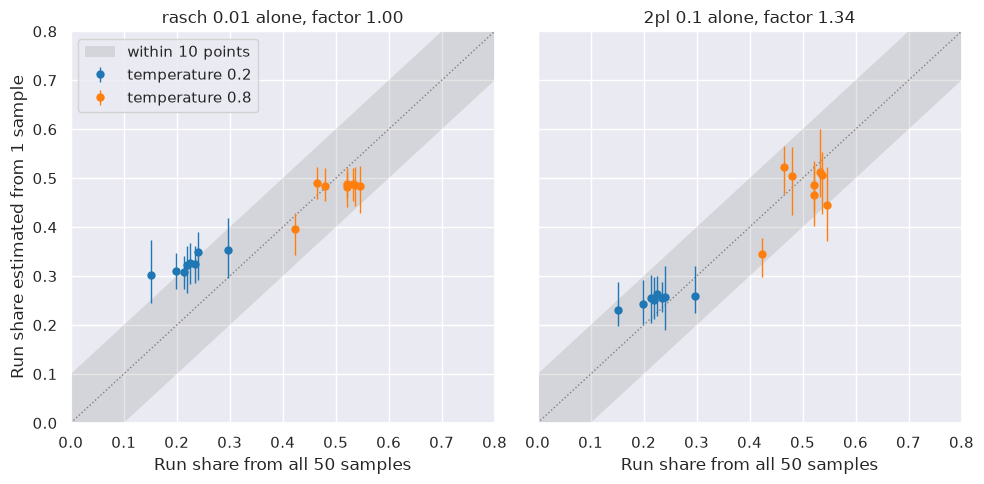

In [11]:
# Plot both settings.
rutils.plot_one_run_estimates(all_results, factors, figsize=(10, 5))
# Outcome: after tuning, both temperatures sit in the band, but within a
# temperature the estimate does not follow the truth: at 0.2 all the models
# are estimated near 25% while the truth goes from 15% to 30%. The estimator
# finds how much run luck there is at a temperature, not which model has more.

# Part 4: How many tasks need a second run

## Cell 4.1: Second runs on some tasks

- Instead of a model of the tasks, a second run of some tasks measures the
  run share directly: on those tasks, half the squared difference of the 2
  runs estimates p (1 - p) without bias
- For each case, the first 2 samples play the 2 runs, and the number shown
  is the smallest number of tasks with a second run such that 95% of the
  random picks of those tasks are within 10 points of the truth

In [12]:
# Find how many tasks need a second run in each case.
second_runs = pd.DataFrame(
    {
        temperature: {
            model: rutils.compute_second_run_tasks(matrix)
            for model, matrix in by_model.items()
        }
        for temperature, by_model in samples.items()
    }
)

display(second_runs)
# Outcome: to be within 10 points 95% of the time, 73 to 162 of the 164 tasks
# need a second run, and for CodeGen 16B at 0.8 even a second run of every task
# is not enough with these 2 samples: measuring run luck directly costs close
# to a full second run.

,0.2,0.8
code-llama-13b,93.0,118.0
code-llama-34b,96.0,162.0
code-llama-7b,98.0,127.0
codegen-16b,156.0,NaN
codet5p-16b,141.0,130.0
mistral-7b,95.0,138.0
phind-code-llama-34b-v2,73.0,105.0
starcoder,100.0,150.0


# Part 5: Takeaways

- From 1 run, a 2PL fit of agents that all ran at the same temperature
  estimates the run share within 10 points in 86% of the draws on the public
  samples, after a calibration factor fit on the other models
- The estimate sees the temperature only through the other agents in the
  matrix: the public greedy agents, which have no run luck, flattened it,
  and every setting with them got worse
- Before tuning, the estimate is too high at 0.2 and close at 0.8; 12 of the
  18 phase-2 test cases are at 0.8, so B2 (above the truth in more than half
  of them) may not hold
- The estimator finds the level of run luck at each temperature, but not
  which model has more
- Measuring run luck directly needs a second run on 45% to 99% of the tasks
  to be as reliable
- The tuned setting is the best of 21 on the same 16 cases, so its error here
  is optimistic; it is frozen in `TUNED_ONE_RUN_SETTING`, and the test on our
  30 cases comes after it is committed